[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

构建 oracle 与扩散算子，在本地放大目标态并保留可选云端示例。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。量子云步骤默认关闭；只有需要访问云端时才将 `RUN_ON_QCLOUD` 改为 `True`，并在启动 Jupyter 前准备好 `APIKEY` 环境变量。

In [1]:
RUN_ON_QCLOUD = False

if RUN_ON_QCLOUD:
    import os
    if not os.environ.get("APIKEY"):
        raise ValueError("请先设置 APIKEY 环境变量，再开启量子云步骤。")


# Grover搜索算法

In [2]:
import os
from math import ceil, pi, sqrt, floor
from typing import List
from pyqpanda3.core import X, H, Z, measure, QProg, CPUQVM
from pyqpanda3.qcloud import QCloudOptions, QCloudService, QCloudJob

In [3]:
def init_state(qubits: List[int]) -> QProg:
    prog = QProg()
    for q in qubits:
        prog << H(q)
    return prog

In [4]:
def build_oracle(qubits: List[int], dst: str) -> QProg:
    prog = QProg()
    n_qubits = len(qubits)
    for idx in range(n_qubits):
        if dst[idx] == '0':
            prog << X(qubits[n_qubits - 1 - idx])
    
    prog << Z(qubits[0]).control(qubits[1:])

    for idx in range(n_qubits):
        if dst[idx] == '0':
            prog << X(qubits[n_qubits - 1 - idx])
    return prog

In [5]:
def build_diffusion(qubits: List[int]) -> QProg:
    prog = QProg()
    for q in qubits:
        prog << H(q) << X(q)
    
    prog << Z(qubits[0]).control(qubits[1:])

    for q in qubits:
        prog << X(q) << H(q)
    return prog

In [6]:
n_qubits = 3
working_qubits = [0, 1, 2]
dst = '010'

prog = QProg()
prog << init_state(working_qubits)

iterations = pi/4*sqrt(2**n_qubits)
iterations = floor(iterations)

oracle = build_oracle(working_qubits, dst)
diffusion = build_diffusion(working_qubits)

for i in range(iterations):
	prog << oracle
	prog << diffusion

for q in working_qubits:
	prog << measure(q, q)

## 本地模拟

先用 CPUQVM 验证目标态概率，再按需开启下一步的量子云运行。

In [7]:
qvm = CPUQVM()
qvm.run(prog, 1000)
local_counts = qvm.result().get_counts()
print(local_counts)
print("目标态：", dst)


{'101': 10, '000': 9, '100': 8, '001': 11, '010': 941, '011': 9, '110': 7, '111': 5}
目标态： 010


## 可选：量子云运行

In [8]:
if RUN_ON_QCLOUD:
    APIKEY = os.getenv('APIKEY')
    service = QCloudService(APIKEY)

    # 查看可用计算后端
    backends = service.backends()
    print(backends)

    # WK_C180是真机，选择使用这个后端
    backend = service.backend('WK_C180')
    options = QCloudOptions()
    job = backend.run(prog, 10000, options)
    # 查询任务结果，计算时间与任务队列中任务数量有关
    result = job.result().get_probs()
    print(result)
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

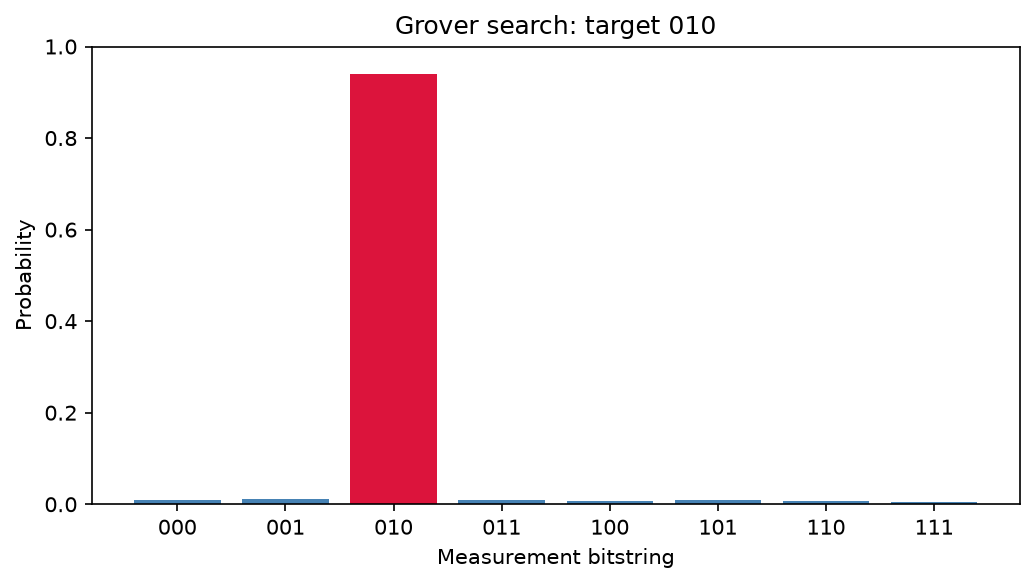

In [9]:
from io import BytesIO
from IPython.display import Image, display
import matplotlib.pyplot as plt

states = [format(i, f"0{n_qubits}b") for i in range(2**n_qubits)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(states, [local_counts.get(state, 0) / sum(local_counts.values()) for state in states], color=["crimson" if state == dst else "steelblue" for state in states])
ax.set(xlabel="Measurement bitstring", ylabel="Probability", ylim=(0, 1), title=f"Grover search: target {dst}")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(data=image_buffer.getvalue()))
